Adding the first code cell

In [1]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "mvtec-ad" / "bottle"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Use Apple's Metal GPU when available
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Image settings
IMAGE_SIZE = 256
BATCH_SIZE = 16

print("Device:", DEVICE)
print("Training images:", DATA_ROOT / "train" / "good")
print("Model output directory:", MODEL_DIR)


Device: mps
Training images: /Users/anupamguptaroy17/Projects/VisionQC/data/raw/mvtec-ad/bottle/train/good
Model output directory: /Users/anupamguptaroy17/Projects/VisionQC/models


Creating the Training Dataset Loader

In [2]:

class BottleDataset(Dataset):
    """Loads normal bottle images for autoencoder training."""

    def __init__(self, image_dir, image_size=256):
        self.image_paths = sorted(Path(image_dir).glob("*.png"))

        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        with Image.open(self.image_paths[index]) as image:
            return self.transform(image.convert("RGB"))


train_dataset = BottleDataset(
    DATA_ROOT / "train" / "good",
    image_size=IMAGE_SIZE,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,  # Smaller batches reduce memory use at higher resolution.
    shuffle=True,
    num_workers=0,
)

sample_batch = next(iter(train_loader))

print("Image size:", IMAGE_SIZE)
print("Training images:", len(train_dataset))
print("Number of batches:", len(train_loader))
print("Batch shape:", sample_batch.shape)
print("Device:", DEVICE)


Image size: 256
Training images: 209
Number of batches: 27
Batch shape: torch.Size([8, 3, 256, 256])
Device: mps


Building the autoencoder model

In [3]:

class BottleAutoencoder(nn.Module):
    """Convolutional autoencoder for bottle anomaly detection."""

    def __init__(self):
        super().__init__()

        # Encoder: compress the input image into a smaller representation.
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),
        )

        # Decoder: reconstruct the original image dimensions.
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                128, 64, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                64, 32, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                32, 16, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                16, 3, kernel_size=4, stride=2, padding=1
            ),
            nn.Sigmoid(),
        )

    def forward(self, x):
        encoded = self.encoder(x)
        reconstructed = self.decoder(encoded)
        return reconstructed



# Create a fresh model; do not reuse the trained baseline weights.
model = BottleAutoencoder().to(DEVICE)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
)

NUM_EPOCHS = 30

# Verify the model accepts 256x256 images.
with torch.no_grad():
    sample_input = sample_batch[:1].to(DEVICE)
    sample_output = model(sample_input)

print("Model device:", next(model.parameters()).device)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))



Model device: mps:0
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 3, 256, 256])
Trainable parameters: 270355


Configuring the training process

In [4]:

# Loss function: measures the difference between original
# and reconstructed bottle images.
criterion = nn.MSELoss()

# Adam optimiser updates the model's weights during training.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of complete passes through the training dataset.
NUM_EPOCHS = 30

print("Loss function:", criterion)
print("Optimiser:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", NUM_EPOCHS)
print("Device:", DEVICE)


Loss function: MSELoss()
Optimiser: Adam
Learning rate: 0.001
Epochs: 30
Device: mps


Train the autoencoder

In [5]:

epoch_losses = []

model.train()

for epoch in range(NUM_EPOCHS):
    running_loss = 0.0

    for images in train_loader:
        images = images.to(DEVICE)

        optimizer.zero_grad()

        reconstructed = model(images)
        loss = criterion(reconstructed, images)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)
    epoch_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] "
        f"Loss: {epoch_loss:.6f}"
    )

print("\nHigher-resolution training complete!")
print(f"Final training loss: {epoch_losses[-1]:.6f}")

# Save the improved model separately from the baseline.
model_path = MODEL_DIR / "bottle_autoencoder_256.pth"
torch.save(model.state_dict(), model_path)

print("Model saved to:", model_path)


Epoch [01/30] Loss: 0.098863
Epoch [02/30] Loss: 0.017990
Epoch [03/30] Loss: 0.007061
Epoch [04/30] Loss: 0.004522
Epoch [05/30] Loss: 0.003793
Epoch [06/30] Loss: 0.003184
Epoch [07/30] Loss: 0.002938
Epoch [08/30] Loss: 0.002804
Epoch [09/30] Loss: 0.003099
Epoch [10/30] Loss: 0.002605
Epoch [11/30] Loss: 0.002417
Epoch [12/30] Loss: 0.002396
Epoch [13/30] Loss: 0.002345
Epoch [14/30] Loss: 0.002302
Epoch [15/30] Loss: 0.002343
Epoch [16/30] Loss: 0.002262
Epoch [17/30] Loss: 0.002272
Epoch [18/30] Loss: 0.002215
Epoch [19/30] Loss: 0.002239
Epoch [20/30] Loss: 0.002173
Epoch [21/30] Loss: 0.002158
Epoch [22/30] Loss: 0.002128
Epoch [23/30] Loss: 0.002136
Epoch [24/30] Loss: 0.002146
Epoch [25/30] Loss: 0.002094
Epoch [26/30] Loss: 0.002078
Epoch [27/30] Loss: 0.002035
Epoch [28/30] Loss: 0.002064
Epoch [29/30] Loss: 0.002026
Epoch [30/30] Loss: 0.001997

Higher-resolution training complete!
Final training loss: 0.001997
Model saved to: /Users/anupamguptaroy17/Projects/VisionQC/mode

Visualising the reconstruction

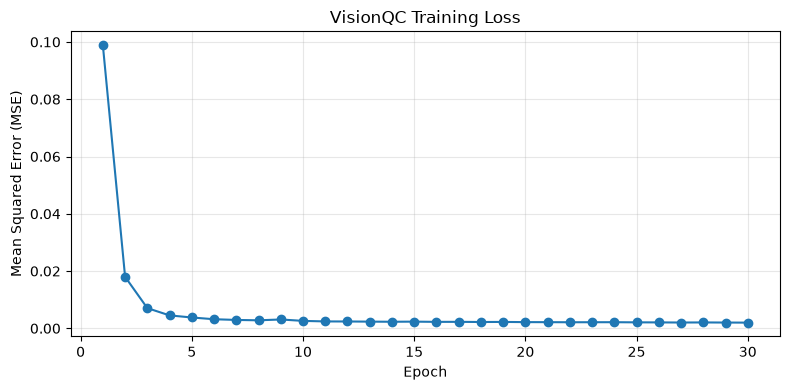

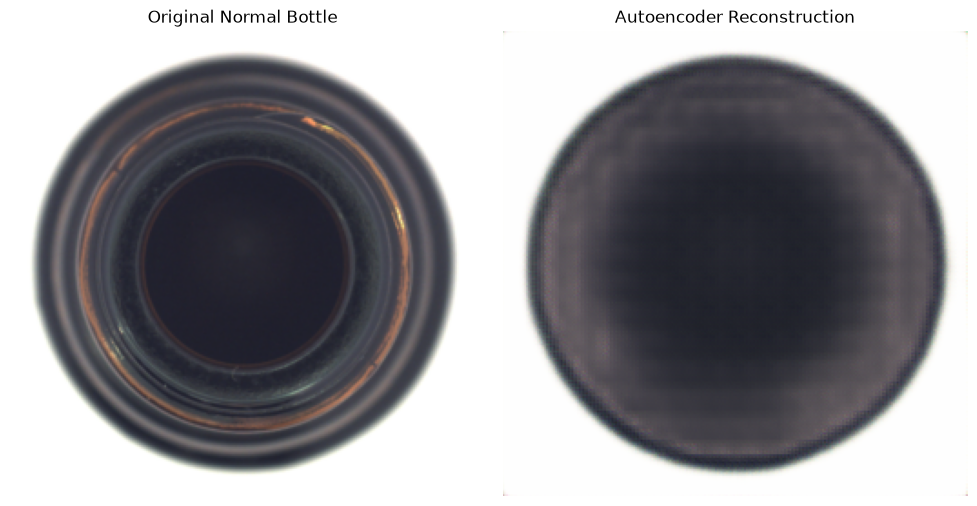

In [7]:

# Plot training loss across epochs.
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o")
plt.title("VisionQC Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Compare an original normal bottle with its reconstruction.
model.eval()

with torch.no_grad():
    original = sample_batch[:1].to(DEVICE)
    reconstructed = model(original)

original_image = original[0].cpu().permute(1, 2, 0).numpy()
reconstructed_image = reconstructed[0].cpu().permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Normal Bottle")
axes[0].axis("off")

axes[1].imshow(reconstructed_image)
axes[1].set_title("Autoencoder Reconstruction")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [9]:
def load_image_tensor(path):
    with Image.open(path) as image:
        image = image.convert("RGB")
        image = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))(image)
        return transforms.ToTensor()(image)

Inspecting the new reconstruction

Reconstruction MSE: 0.002388


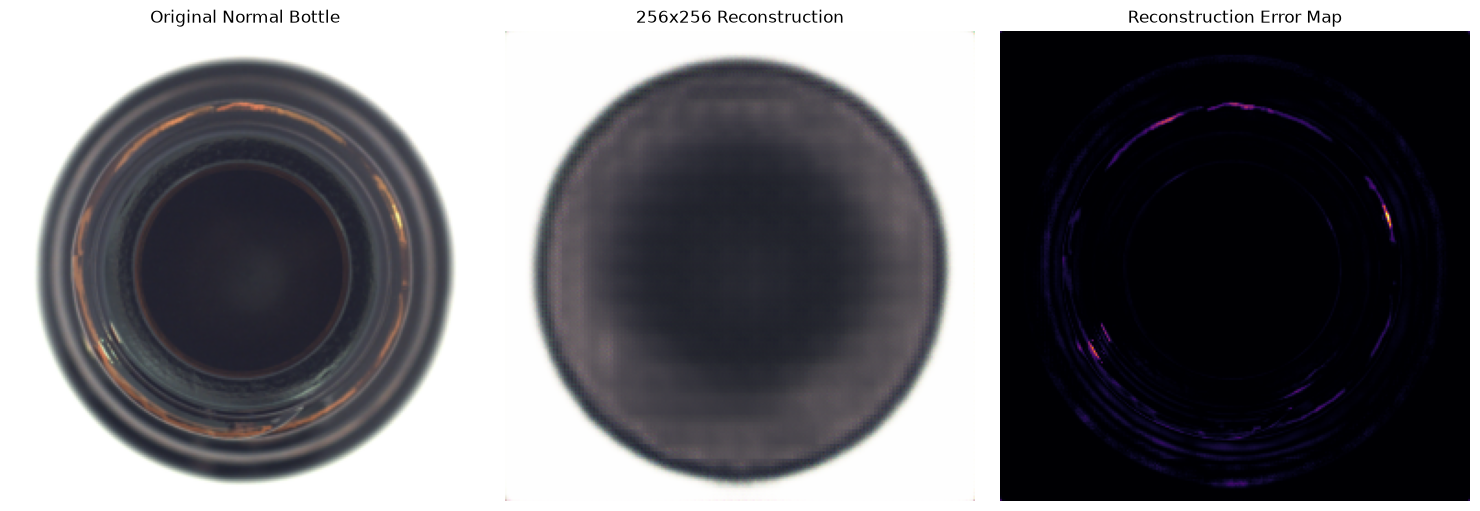

In [10]:

# Load a normal bottle at the new resolution.
normal_path = DATA_ROOT / "test" / "good" / "000.png"
normal_tensor = load_image_tensor(normal_path).unsqueeze(0).to(DEVICE)

model.eval()

with torch.no_grad():
    normal_reconstruction = model(normal_tensor)

original_array = (
    normal_tensor[0].cpu().permute(1, 2, 0).numpy()
)
reconstructed_array = (
    normal_reconstruction[0].cpu().permute(1, 2, 0).numpy()
)

error_map = np.mean(
    (original_array - reconstructed_array) ** 2,
    axis=2,
)

print(f"Reconstruction MSE: {error_map.mean():.6f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_array)
axes[0].set_title("Original Normal Bottle")
axes[0].axis("off")

axes[1].imshow(reconstructed_array)
axes[1].set_title("256x256 Reconstruction")
axes[1].axis("off")

axes[2].imshow(error_map, cmap="inferno")
axes[2].set_title("Reconstruction Error Map")
axes[2].axis("off")

plt.tight_layout()
plt.show()


Comparing normal and defective bottles

In [11]:
normal_path = DATA_ROOT / "test" / "good" / "000.png"
defect_path = DATA_ROOT / "test" / "broken_small" / "002.png"

normal_tensor = load_image_tensor(normal_path).unsqueeze(0).to(DEVICE)
defect_tensor = load_image_tensor(defect_path).unsqueeze(0).to(DEVICE)

model.eval()

with torch.no_grad():
    normal_reconstruction = model(normal_tensor)
    defect_reconstruction = model(defect_tensor)

normal_error = torch.mean(
    (normal_tensor - normal_reconstruction) ** 2
).item()

defect_error = torch.mean(
    (defect_tensor - defect_reconstruction) ** 2
).item()

print(f"Normal bottle error:   {normal_error:.6f}")
print(f"Defective bottle error: {defect_error:.6f}")
print(f"Error difference:       {defect_error - normal_error:.6f}")

Normal bottle error:   0.002388
Defective bottle error: 0.003127
Error difference:       0.000740


Visualising the results

NameError: name 'normal_image' is not defined

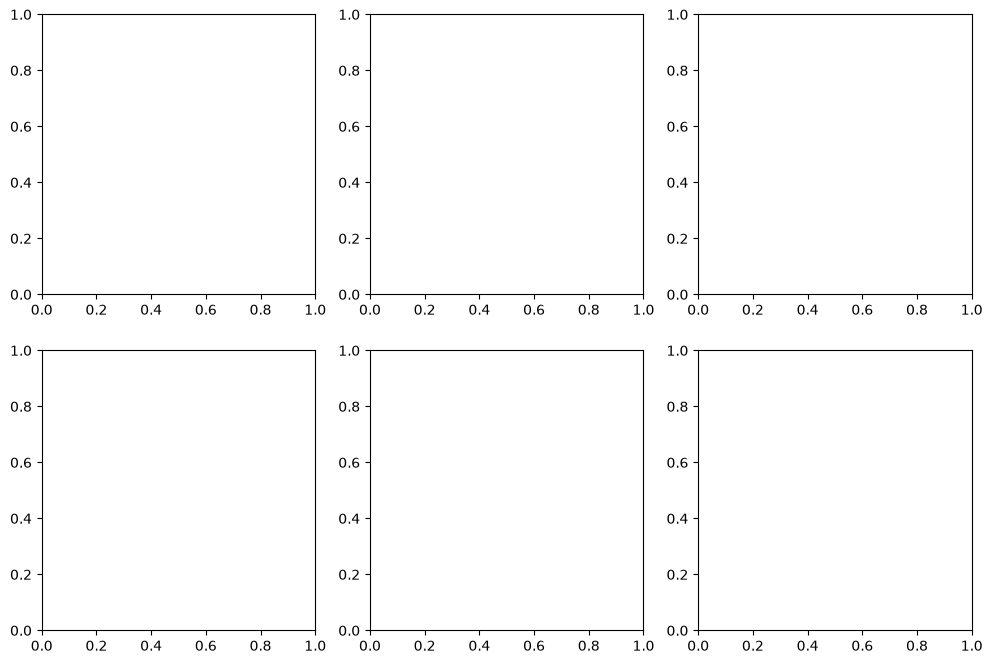

In [12]:

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

images = [
    normal_image, normal_reconstruction, normal_error_map,
    defect_image, defect_reconstruction, defect_error_map,
]

titles = [
    "Normal: Original", "Normal: Reconstructed", "Normal: Error Map",
    "Defective: Original", "Defective: Reconstructed", "Defective: Error Map",
]

for ax, image, title in zip(axes.flat, images, titles):
    array = image[0].detach().cpu().numpy()

    if array.ndim == 3 and array.shape[0] == 3:
        array = np.transpose(array, (1, 2, 0))
        ax.imshow(array)
    else:
        ax.imshow(array, cmap="inferno")

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


Evaluating all 83 Images

In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

# 1. Load every image at the correct resolution (256x256).
def load_image_tensor(path):
    with Image.open(path) as image:
        image = image.convert("RGB")
        image = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))(image)
        return transforms.ToTensor()(image)


# 2. Calculate the pixel-wise reconstruction error map.
def get_reconstruction(image_tensor):
    model.eval()

    with torch.no_grad():
        image_tensor = image_tensor.to(DEVICE)
        reconstruction = model(image_tensor)
        error_map = (image_tensor - reconstruction).pow(2).mean(dim=1)

    return error_map[0].cpu().numpy()


model.eval()

# 3. Calibrate a provisional threshold using normal training images.
train_scores = []

for path in sorted((DATA_ROOT / "train" / "good").glob("*.png")):
    tensor = load_image_tensor(path).unsqueeze(0)
    error_map = get_reconstruction(tensor)
    train_scores.append(float(error_map.mean()))

threshold = float(np.percentile(train_scores, 99))

print(f"Image resolution: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Provisional anomaly threshold: {threshold:.6f}")

# 4. Evaluate all test images.
true_labels = []
predicted_labels = []
image_scores = []
pixel_errors = []
pixel_labels = []

for category in sorted(
    p.name for p in (DATA_ROOT / "test").iterdir() if p.is_dir()
):
    for path in sorted((DATA_ROOT / "test" / category).glob("*.png")):
        is_defective = category != "good"

        tensor = load_image_tensor(path).unsqueeze(0)
        error_map = get_reconstruction(tensor)
        score = float(error_map.mean())

        true_labels.append(int(is_defective))
        predicted_labels.append(int(score > threshold))
        image_scores.append(score)

        # Load the ground-truth defect mask.
        if is_defective:
            mask_path = (
                DATA_ROOT / "ground_truth" / category
                / f"{path.stem}_mask.png"
            )

            with Image.open(mask_path) as mask_image:
                mask_image = mask_image.convert("L").resize(
                    (IMAGE_SIZE, IMAGE_SIZE),
                    Image.Resampling.NEAREST,
                )
                mask = np.asarray(mask_image) > 0
        else:
            mask = np.zeros(
                (IMAGE_SIZE, IMAGE_SIZE), dtype=bool
            )

        pixel_errors.extend(error_map.ravel())
        pixel_labels.extend(mask.ravel())

# 5. Report image-level detection metrics.
print("\nIMAGE-LEVEL RESULTS")
print("Test images:", len(true_labels))
print(f"Accuracy:  {accuracy_score(true_labels, predicted_labels):.3f}")
print(f"Precision: {precision_score(true_labels, predicted_labels, zero_division=0):.3f}")
print(f"Recall:    {recall_score(true_labels, predicted_labels, zero_division=0):.3f}")
print(f"F1 score:  {f1_score(true_labels, predicted_labels, zero_division=0):.3f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(true_labels, predicted_labels))

# 6. Report pixel-level localisation performance.
print("\nLOCALISATION RESULTS")

try:
    pixel_auc = roc_auc_score(pixel_labels, pixel_errors)
    print(f"Pixel-level ROC-AUC: {pixel_auc:.3f}")
except ValueError:
    print("Pixel-level ROC-AUC could not be calculated.")

print("\nEvaluation complete.")


Image resolution: 256x256
Provisional anomaly threshold: 0.002811

IMAGE-LEVEL RESULTS
Test images: 83
Accuracy:  0.518
Precision: 0.960
Recall:    0.381
F1 score:  0.545
Confusion matrix [[TN, FP], [FN, TP]]:
[[19  1]
 [39 24]]

LOCALISATION RESULTS
Pixel-level ROC-AUC: 0.681

Evaluation complete.


Comparing different thresolds

In [10]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

thresholds = [
    threshold * 0.50,
    threshold * 0.65,
    threshold * 0.80,
    threshold,
    threshold * 1.20,
]

print(f"{'Threshold':>12} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>10} {'F1':>10} {'False alarms':>14} {'Missed defects':>15}")

for t in thresholds:
    predictions = (np.array(image_scores) > t).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        true_labels, predictions, labels=[0, 1]
    ).ravel()

    print(
        f"{t:12.6f} "
        f"{accuracy_score(true_labels, predictions):10.3f} "
        f"{precision_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{recall_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{f1_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{fp:14d} {fn:15d}"
    )


   Threshold   Accuracy  Precision     Recall         F1   False alarms  Missed defects
    0.001327      0.759      0.759      1.000      0.863             20               0
    0.001725      0.759      0.759      1.000      0.863             20               0
    0.002123      0.771      0.814      0.905      0.857             13               6
    0.002653      0.651      0.947      0.571      0.713              2              27
    0.003184      0.506      1.000      0.349      0.518              0              41
